This example guides you through a simple, yet complete, example of how to go from ntuples to training a graph network. In particular it shows how to:
- Read jet constituents from a .root file, build graphs in either the Euclidian or Lund geometries, and store them for later use
- Load graph datasets accounting for event weights, merging multiple samples, and split the data in taining/testing
- Define and train a graph network
- Evaluate the performance of the graph network at the task at hand

A graph is an _unordered_ set of objects, called **nodes**, connected to each other via **edges**:

<img src="images/graph.png" width=200>

Each node $x_i$ and edge $a_{ij}$ can be assigned a (set of) features.

Graphs are a more natural representation of jets compared to tabular (arrays of features) of images: compared to the former, thay lift the limitation of having the number of features fixed for every example, allowing for e.g., using the 4-momenta of constituents directly; compared to the latter, they circumvent the issue of sparsity and are rotationally invariant by construction.

Though there are many ways to represent a jet as a graph, two of them are available in this package:
- So-called spacial graphs, based on the distribution of constituents in the $(\eta,\phi)$ plane. Each constituent is a node, with connections being added between nodes that are closer in $\Delta R=\sqrt{\Delta\eta^2 + \Delta\phi^2}$ then a given threshold:

<img src="images/spacial_graph.png" width=600>

- Lund graphs, based on the Cambridge-Aachen clustering pattern. Starting from the constituents of the jet, these are pairwise clustered together by adding their 4-momenta. The clustering proceeds recursively until all constituents are added together to form the original jet. Keeping track of each merging step, a binary tree is constructed, called the Lund tree:

<img src="images/lund_graph.png" width=800>

At each node (i.e., clustering step) a set of features are calculated, called Lund variables. These are:
- $\Delta = \sqrt{(\eta_i - \eta_j)^2 + (\phi_i -\phi_j)^2}$
- $k_T = \Delta\cdot\min (p_{T,i},p_{T,j})$
- $\psi = \arctan( (y_{lo} - y_{hi})/(\phi_{lo} - \phi_{hi}) )$ (_lo_ and _hi_ being the indices of the highest and lowest pt constituent of the culstered pair, respectively)
- $z = \min(p_{T,i},p_{T,j})/(p_{T,i} + p_{T,j})$
- The invariant mass of the clustered pair

Optionally, the 4-momenta of the clustered pair can be stored as well. Finally, the energy fractions i.e., how much of the energy of a given pseudojet (a node) comes from electrons, muons, photons, or hadrons.

The first step is to load (and process, if neccessary) the graph dataset. This is handled by the `utils.JetGraphProducer` module. The underlying package that we use is [PyTorch Geometric](https://pytorch-geometric.readthedocs.io/en/latest/) (PyG) - an extension of [PyTorch](https://pytorch.org/) that handles graphs.

In [ ]:
from svj_tools.utils.JetGraphProducer import JetGraphProducer
from svj_tools.utils.LundTreeUtilities import OnTheFlyNormalizer
import torch

# Produce the graphs. The call to JetGraphProducer will produce the graphs and
# save them in the specified directory if it is not already present.
qcd = JetGraphProducer(
        "test_data/qcd/", # Path to the directory containing the root files to be processed
        "QCD_large", # Name to be given to the produced dataset (or the name of the dataset if it is already present)
        n_store_jets=2, # Number of jets to process per event, in order of decreasing pT
        # max_events_to_process=100, # Maximum number of events to process (set to None to process all events)
        use_lund_decomp=True, # Whether to use the Lund decomposition
        n_lund_vars=5, # Number of variables to store in the Lund decomposition (3 or 5)
        save_energy_fractions=True, # Whether to save the energy fractions of the pseudojets in the Lund graph
        save_4vectors_in_lund_tree=True, # Whether to save the 4-vectors of the pseudojets in the Lund graph
        weights="xsec", # Weights to be applied to the graphs (None, "xsec")
        verbose=True, # Whether to print the progress of the processing
        label=0, # Label to be assigned to the graphs (for supervised learning)
    )

s1 = JetGraphProducer(
        "test_data/rinv_0p3",
        "SVJ_3100_0p3_large",
        n_store_jets=2,
        # max_events_to_process=100,
        use_lund_decomp=True,
        n_lund_vars=5,
        save_energy_fractions=True,
        save_4vectors_in_lund_tree=True,
        weights="xsec",
        verbose=True,
        label=1,
    )

s2 = JetGraphProducer(
        "test_data/rinv_0p5",
        "SVJ_3100_0p5_large",
        n_store_jets=2,
        # max_events_to_process=100,
        use_lund_decomp=True,
        n_lund_vars=5,
        save_energy_fractions=True,
        save_4vectors_in_lund_tree=True,
        weights="xsec",
        verbose=True,
        label=1,
    )

# Compute the means and stds for the normalizer (if required)
means, stds = 0., 0.
weights = []
counts = []

for graph in qcd:
    means += graph.x.sum(dim=0)*graph.w
    weights.append(graph.w)
    counts.append(graph.num_nodes)
means /= sum(torch.tensor(weights)*torch.tensor(counts))

for graph in qcd:
    stds += ((graph.x - means)**2).sum(dim=0)*graph.w

stds /= sum(torch.tensor(weights)*torch.tensor(counts))
stds = torch.sqrt(stds)

normalizer = OnTheFlyNormalizer(["x"], means, stds)

The JetGraphProducer returns a `torch_geometric.data.InMemoryDataset` object. For now, this can be thought of as a list of graphs (though the reality is a bit more complicated):

In [2]:
print(qcd[0])

Data(x=[141, 12], edge_index=[2, 280], y=[1], num_node_features=[1], w=[1], num_nodes=141)


Each graph has a number of features, the most important ones for now being `.x` and `.edge_index`. The `.x` attribute contains the features of each nodes, stored in a $N_{nodes}\times N_{features}$ dimensional tensor

In [3]:
print(qcd[0].x.shape)
print(qcd[0].x)

torch.Size([141, 12])
tensor([[0.0000e+00, 0.0000e+00, 1.0000e+00,  ..., 0.0000e+00, 1.0000e+00,
         0.0000e+00],
        [0.0000e+00, 0.0000e+00, 1.0000e+00,  ..., 0.0000e+00, 0.0000e+00,
         1.0000e+00],
        [0.0000e+00, 0.0000e+00, 1.0000e+00,  ..., 0.0000e+00, 1.0000e+00,
         0.0000e+00],
        ...,
        [2.7735e+00, 5.0019e-01, 5.1373e-03,  ..., 0.0000e+00, 5.3694e-01,
         4.6308e-01],
        [2.4776e+00, 6.9797e-01, 3.2790e-03,  ..., 0.0000e+00, 5.3514e-01,
         4.6489e-01],
        [6.0626e-01, 7.9286e-01, 7.0632e-04,  ..., 0.0000e+00, 5.3474e-01,
         4.6528e-01]])


The `.edge_index` attribute stores the connections between nodes encoded in an adjacency matrix. This is a $N_{nodes}\times N_{nodes}$ dimensional tensor whose element $a_{ij}$ is 1 if nodes $i$ and $j$ are connected and 0 if they are not:

In [4]:
from torch_geometric.utils import to_dense_adj

print(to_dense_adj(qcd[0].edge_index))

tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 1., 0.],
         [0., 0., 0.,  ..., 1., 0., 1.],
         [0., 0., 0.,  ..., 0., 1., 0.]]])


Notice the extra step of passing the tensor through the `to_dense_adj` function. This is because PyG uses the sparse representation by default, in which the adjacency matrix is stored as a $2\times N_{edges}$ tensor in which elements $a_{0,k}$ and $a_{1,k}$ contain the origin and target nodes of edge $k$. We will be working with undirected graphs, meaning that edges "go both ways". This is achieved by having two pairs for each edge with $a_{0,k+1}=a_{1,k}$ and $a_{0,k}=a_{1,k+1}$:

In [5]:
print(qcd[0].edge_index.shape)
print(qcd[0].edge_index)

torch.Size([2, 280])
tensor([[  2,  12,  71,  71,   0,   1,  72,  72,   5,  19,  73,  73,   3,  10,
          74,  74,   7,  18,  75,  75,  72,  74,  76,  76,  15,  16,  77,  77,
          21,  29,  78,  78,  76,  77,  79,  79,   6,  73,  80,  80,  13,  71,
          81,  81,   9,  22,  82,  82,  79,  80,  83,  83,  81,  82,  84,  84,
           4,  75,  85,  85,  26,  78,  86,  86,  30,  54,  87,  87,  17,  37,
          88,  88,  40,  69,  89,  89,  11,  84,  90,  90,  25,  43,  91,  91,
          28,  36,  92,  92,  83,  85,  93,  93,  14,  45,  94,  94,  38,  88,
          95,  95,   8,  90,  96,  96,  24,  31,  97,  97,  68,  89,  98,  98,
          23,  46,  99,  99,  35,  56, 100, 100,  34,  59, 101, 101,  51,  87,
         102, 102,  86,  92, 103, 103,  60,  98, 104, 104,  95,  99, 105, 105,
          93,  96, 106, 106,  55,  58, 107, 107,  33,  66, 108, 108, 101, 104,
         109, 109,  47, 103, 110, 110,  32,  97, 111, 111,  61,  94, 112, 112,
          27,  67, 113, 113,  5

In this example, the submatrix [[2, 12, 71, 71], [71, 71, 2, 12]] means that there is a bi-directional edge between nodes 2 and 71, and another one between nodes 12 and 71. We can also plot the lund graphs, to get a feel for what we are working with and, more importantly, because they are gorgeus :) The order of observables in this example is $[k_T, \Delta, z, \psi, p_T, \eta, \phi, m, f_e, f_\mu, f_\gamma, f_h]$

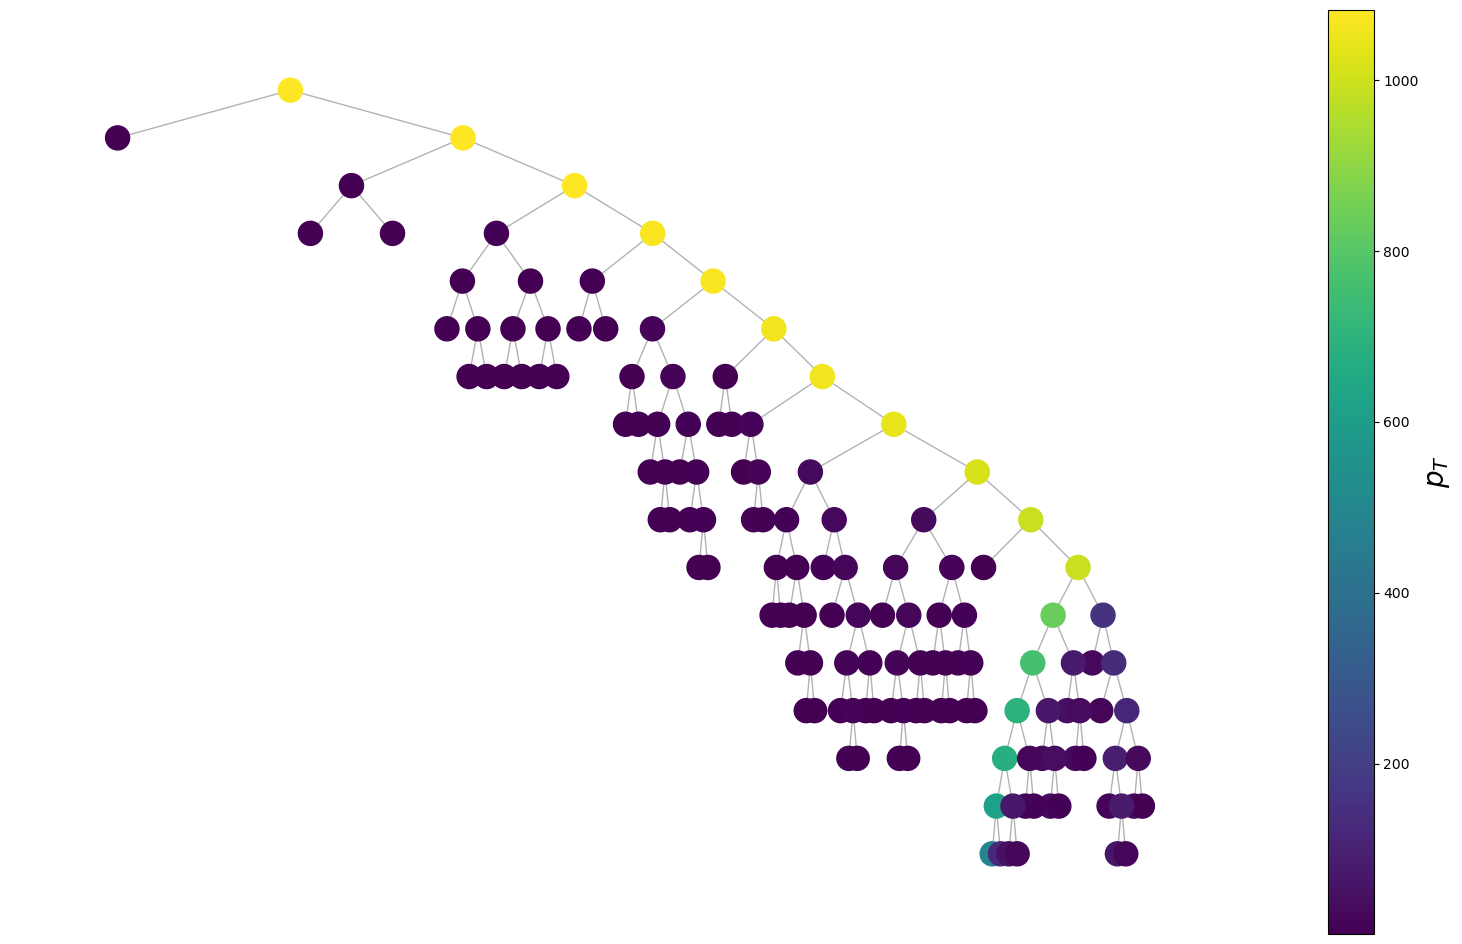

In [ ]:
from svj_tools.utils.PlotUtils import plot_tree

# Plot a nice Lund tree
plot_tree(qcd[0], 4, "$p_T$", "myTree", show=True)

The next step is loading the data in a form that can be used to train a network. This is handled by the `data_loading.graphDataLoader` module. It allows you:
- Concatenate different datasets (e.g., QCD and $t\bar{t}$ into a single background dataset)
- Splitting the data into training/validation/testing parts
- Normalize the graphs across the datasets (an extremely delicate step due to how PyG handles memory)
- Batch the data
- Sample the data according to the event weight distribution

In [ ]:
from svj_tools.data_loading.graphDataLoader import GraphDataLoader

# Create the data loaders for training and testing. Note how
# you can concatenate multiple datasets in a single loader and how
# you can specify the window of each dataset to load.
loader_training = GraphDataLoader(
    [
        [
            "test_data/qcd", # path to the dataset
            "QCD_large", # name of the dataset (you can process the same raw data with multiple settings given each a different name)
        ],
    ],
    window_to_load=[[0., 0.7]],
    batch_size=64,
    normalizer=normalizer,
)

loader_testing = GraphDataLoader(
    [
        ["test_data/qcd", "QCD_large"]
    ],
    window_to_load=[[0.7, 1.]],
    normalizer=normalizer,
)

loader_signal = GraphDataLoader(
    [
        ["test_data/rinv_0p3", "SVJ_3100_0p3_large"],
        ["test_data/rinv_0p5", "SVJ_3100_0p5_large"],
    ],
    window_to_load=[[0., 1.] for _ in range(2)],
    normalizer=normalizer,
)

c:\Users\sgnas\micromamba\envs\gnn\Lib\site-packages\torch_geometric\data\in_memory_dataset.py:300: UserWarning: It is not recommended to directly access the internal storage format `data` of an 'InMemoryDataset'. The given 'InMemoryDataset' only references a subset of examples of the full dataset, but 'data' will contain information of the full dataset. The data of the dataset is already cached, so any modifications to `data` will not be reflected when accessing its elements. Clearing the cache now by removing all elements in `dataset._data_list`. If you are absolutely certain what you are doing, access the internal storage via `InMemoryDataset._data` instead to suppress this warning. Alternatively, you can access stacked individual attributes of every graph via `dataset.{attr_name}`.
  warnings.warn(msg)


We are now ready to define and train a graph autoencoder. A sample architecture is provided in `architectures.GraphAE`, but feel free to be creative :) We also define the optimizer

In [ ]:
from svj_tools.architectures.GraphAE import graphAE
import time
from tqdm import tqdm

# Create the model
model = graphAE(
    num_features=12,
    architecture=(256, 128, 64, 32, 16, 8, 4),
)

# Define the optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

We are now ready to train the network. First, we define enclose one step of the batched gradient descent procedure in a function for the sake of convenience:

In [9]:
from torch_geometric.utils import batched_negative_sampling, negative_sampling

# Train the model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# NB: If you run on the PSI cluster, you should limit the number of threads
# torch.set_num_threads(8)

# Define training function
def train_on_batch(model, batch, optimizer, alpha=1.):
    """
    Train the model for one epoch.

    Args:
    - model (torch.nn.Module): the model to train
    - batch (torch_geometric.data.Data): the batch of data
    - optimizer (torch.optim.Optimizer): the optimizer to use
    - alpha (float): the weight of the features loss in the total loss

    Returns:
    - float: the edges loss
    - float: the features loss
    """

    model.train()
    x = batch.x
    edges = batch.edge_index
    _batch = batch.batch.to(device)

    edges_loss = model.edges_loss(
        x,
        edges,
        # Negative sampling is important to also show the network
        # examples of non-connected nodes
        batched_negative_sampling(
            edges,
            _batch,
        ).to(device),
    )

    features_loss = model.features_loss(x, edges)
    loss = edges_loss + alpha*features_loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return float(edges_loss.detach()), float(features_loss.detach())

Then we train, keeping track of how the loss function evolves. Note that the number of epochs is set very low for demonstration purposes, in your code you will want to increas this by at least a factor 100:

In [10]:
# Train the model
losses = []
losses_edges = []
losses_nodes = []
epochs = 1
alpha = 150

start = time.time()

for epoch in range(epochs):
    for batch in tqdm(loader_training, desc=f"Epoch {epoch}", leave=False):

        loss_edges, loss_features = train_on_batch(model, batch, optimizer, alpha)
        losses.append(loss_edges+alpha*loss_features)
        losses_edges.append(loss_edges)
        losses_nodes.append(alpha*loss_features)

print(f"--> Training completed in {time.time()-start:.2f} seconds")

--> Training completed in 125.42 seconds


We can visualize the evolution of the loss function after the training is complete:

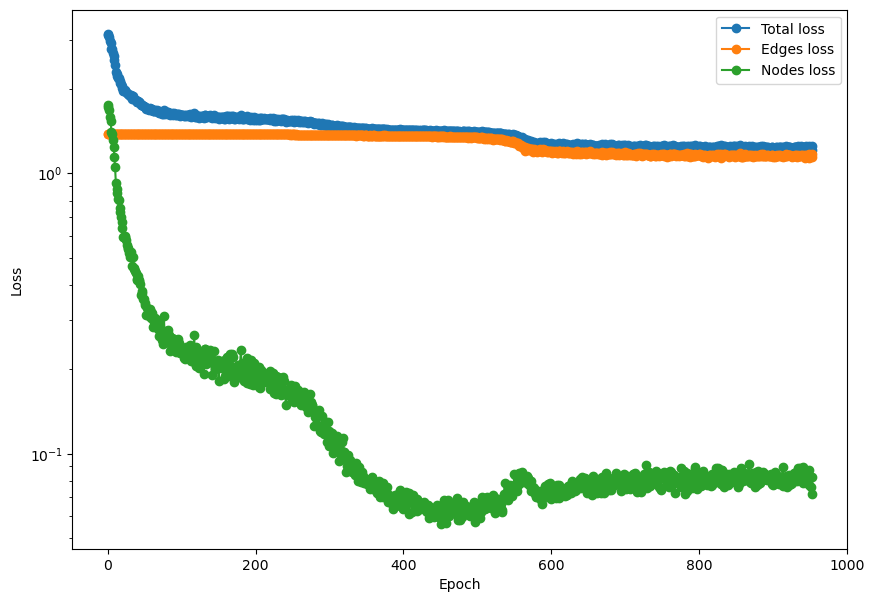

In [11]:
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (10, 7)})

plt.plot(losses, label="Total loss", marker="o")
plt.plot(losses_edges, label="Edges loss", marker="o")
plt.plot(losses_nodes, label="Nodes loss", marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.legend()
plt.show()

To see if the model is achieving what we want it to, we can evaluate its performance on the test dataset by calculating the ROC curve and ROC AUC. They won't look good, but with 1 epoch of training the AE is still basically guessing:

In [12]:
# Evaluate the model on the test set

model.eval()

losses_testing_qcd = []

for graph in tqdm(loader_testing, desc="Testing QCD", leave=True):
    x = graph.x
    edges = graph.edge_index

    edges_loss = model.edges_loss(
        x,
        edges,
        negative_sampling(
            edges,
        ).to(device),
    )

    features_loss = model.features_loss(x, edges)
    loss = edges_loss + alpha*features_loss

    losses_testing_qcd.append(float(loss.detach()))

losses_testing_signal = []

for graph in tqdm(loader_signal, desc="Testing SVJ", leave=True):
    x = graph.x
    edges = graph.edge_index

    edges_loss = model.edges_loss(
        x,
        edges,
        negative_sampling(
            edges,
        ).to(device),
    )

    features_loss = model.features_loss(x, edges)
    loss = edges_loss + alpha*features_loss

    losses_testing_signal.append(float(loss.detach()))

Testing SVJ: 100%|██████████| 13000/13000 [02:24<00:00, 90.03it/s]


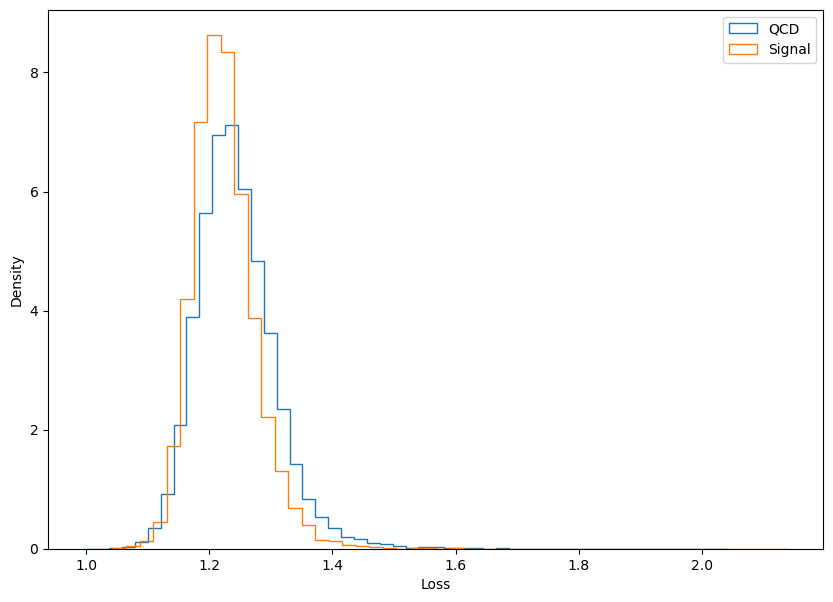

In [13]:
plt.hist(losses_testing_qcd, bins=50, histtype="step", label="QCD", density=True)
plt.hist(losses_testing_signal, bins=50, histtype="step", label="Signal", density=True)
plt.xlabel("Loss")
plt.ylabel("Density")
plt.legend()
plt.show()

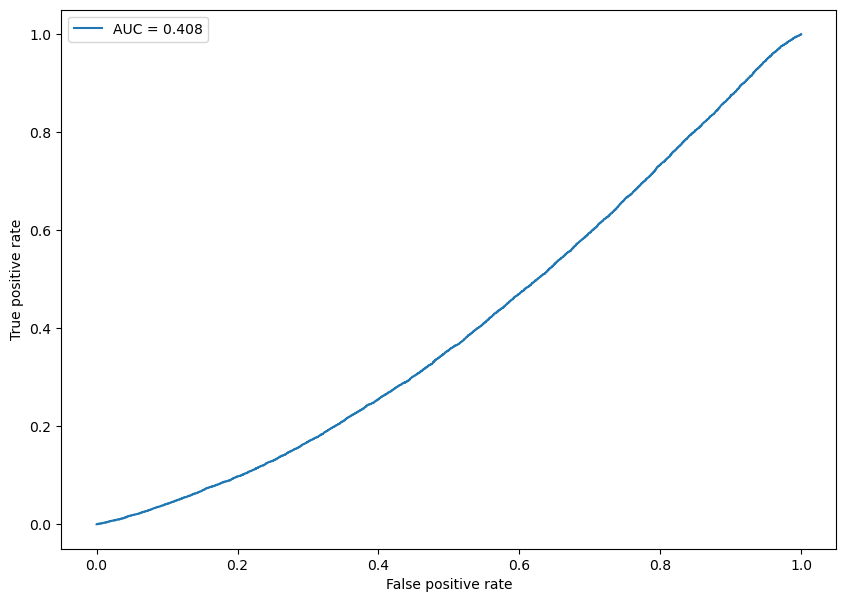

In [14]:
from sklearn.metrics import roc_auc_score, roc_curve

y_true = [0]*len(losses_testing_qcd) + [1]*len(losses_testing_signal)
y_score = losses_testing_qcd + losses_testing_signal

fpr, tpr, _ = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.show()